# Topic 7 — Exploring FIR filters in the z-domain

**An interactive Python companion to the z-transform lecture**  
Inspired by the [DSPFirst PEZ Demo](https://dspfirst.gatech.edu/matlab/#pezdemo) and its [three-domain animations](https://dspfirst.gatech.edu/chapters/07ztrans/demos/3_domain/index.html).

**What you will learn**

1. Convert an FIR coefficient sequence (its impulse response) into the system function $H(z)$.
2. Find and plot the **zeros** of $H(z)$ in the complex z-plane.
3. Obtain the frequency response by following $H(z)$ around the **unit circle** $z=e^{j\omega}$.
4. Move zeros and see, at the same time, what happens to the coefficients, magnitude response, and phase.
5. Design notch filters, running-sum filters, and simple band-pass filters.

**How to use:** Run cells from top to bottom (`Run All`). In the interactive sections, change the sliders or the coefficients and observe all the updated plots. All frequencies $\omega$ are in *radians per sample*; the horizontal plots use $\omega/\pi$.

**Requirements:** `numpy`, `matplotlib`, `IPython`, and `ipywidgets` (for sliders). If necessary, run `%pip install numpy matplotlib ipywidgets` in a new notebook cell and restart the kernel. Static plots and calculations will still work without `ipywidgets`.

## 1. From an impulse response to a system function

An FIR filter of **order** $M$ has $M+1$ coefficients and satisfies

$$y[n]=\sum_{k=0}^{M}h[k]x[n-k].$$

Its **system function** is the z-transform of the impulse response:

$$\boxed{H(z)=\sum_{k=0}^{M}h[k]z^{-k}=h[0]+h[1]z^{-1}+\cdots+h[M]z^{-M}.}$$

The coefficients $h[k]$ appear unchanged in the expression for $H(z)$; only the powers of $z^{-1}$ are added. **Each $z^{-1}$ is a one-sample delay.**

To find zeros, multiply by $z^M$ and solve an ordinary polynomial equation:

$$H(z)=\frac{P(z)}{z^M}, \qquad P(z)=h[0]z^M+h[1]z^{M-1}+\cdots+h[M].$$

Zeros are roots of $P(z)$ away from canceled factors. For an FIR with nonzero final coefficient, $z=0$ is a pole of order $M$ (a consequence of writing delays as negative powers of $z$). These poles do **not** make a causal finite FIR unstable.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

try:
    import ipywidgets as widgets
    HAS_WIDGETS = True
except ImportError:
    HAS_WIDGETS = False
    print("Interactive sliders are unavailable. Install them with: %pip install ipywidgets")

# No special Matplotlib backend is needed: widgets redraw ordinary inline figures.
plt.rcParams.update({"figure.dpi": 105, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

### Helper functions (read them; they are also useful in the exercises)

In the plots, **○** marks a zero, **×** marks a pole, and the circle of radius one is $z=e^{j\omega}$.  
The code evaluates $H(e^{j\omega})$ directly using its FIR coefficients, so no FFT approximation is needed.

In [2]:
def clean_coefficients(values):
    """Remove irrelevant trailing zero taps, but preserve leading delays."""
    h = np.asarray(values, dtype=complex).reshape(-1)
    if len(h) == 0 or not np.all(np.isfinite(h)) or np.all(abs(h) < 1e-12):
        raise ValueError("Enter at least one finite, nonzero FIR coefficient.")
    while len(h) > 1 and abs(h[-1]) < 1e-12:
        h = h[:-1]
    return np.real_if_close(h)


def parse_coefficients(text):
    """Accept coefficients separated by commas or spaces (real values)."""
    tokens = text.replace(";", ",").replace("\n", " ").replace(",", " ").split()
    return clean_coefficients([float(token) for token in tokens])


def fir_response(h, omega):
    """H(exp(j omega)) = sum_k h[k] exp(-j omega k)."""
    h = clean_coefficients(h)
    omega = np.asarray(omega)
    return np.exp(-1j * np.multiply.outer(omega, np.arange(len(h)))) @ h


def hz_on_plane(h, z):
    """H(z) for any complex z != 0."""
    h = clean_coefficients(h)
    z = np.asarray(z, dtype=complex)
    with np.errstate(divide='ignore', invalid='ignore', over='ignore'):
        return np.polyval(h, z) / z**(len(h) - 1)


def fir_roots(h):
    """Finite zeros and pole multiplicity at z=0 (after trimming trailing zero taps)."""
    h = clean_coefficients(h)
    zeros = np.roots(h) if len(h) > 1 else np.array([], dtype=complex)
    return zeros, len(h) - 1


def number_tex(value):
    value = float(np.real(value))
    if abs(value - round(value)) < 1e-9:
        return str(int(round(value)))
    return f"{value:.4g}"


def polynomial_tex(h):
    """A compact LaTeX representation for real-valued coefficients."""
    h = clean_coefficients(h)
    if np.max(np.abs(np.imag(h))) > 1e-10:
        return r"H(z)=\sum_{k=0}^{M}h[k]z^{-k}\;\text{(complex coefficients)}"
    terms = []
    for k, c in enumerate(np.real(h)):
        if abs(c) < 1e-10:
            continue
        abs_c = abs(c)
        coefficient = "" if k and abs(abs_c - 1) < 1e-9 else number_tex(abs_c)
        power = "" if k == 0 else (r"z^{-1}" if k == 1 else rf"z^{{-{k}}}")
        term = coefficient + power
        sign = "-" if c < 0 else "+"
        terms.append((sign, term))
    sign, first = terms[0]
    rest = "".join(" " + sign + " " + term for sign, term in terms[1:])
    return r"H(z)=" + ("-" if sign == "-" else "") + first + rest


def draw_zplane(ax, h, omega_probe=None, show_distances=False):
    zeros, pole_order = fir_roots(h)
    ang = np.linspace(-np.pi, np.pi, 400)
    ax.plot(np.cos(ang), np.sin(ang), '--', lw=1.2, label='unit circle')
    ax.axhline(0, lw=0.7, alpha=.35)
    ax.axvline(0, lw=0.7, alpha=.35)
    if len(zeros):
        ax.scatter(zeros.real, zeros.imag, s=85, marker='o', facecolors='white',
                   edgecolors='C0', linewidths=2, label='zeros', zorder=5)
    if pole_order:
        ax.scatter([0], [0], s=90, marker='x', linewidths=2, color='C3',
                   label=f'pole at 0 (order {pole_order})', zorder=6)
    if omega_probe is not None:
        z_probe = np.exp(1j * omega_probe)
        ax.scatter([z_probe.real], [z_probe.imag], marker='D', s=45,
                   color='C2', label='selected frequency', zorder=7)
        if show_distances and len(zeros) <= 4:
            for zz in zeros:
                ax.plot([z_probe.real, zz.real], [z_probe.imag, zz.imag],
                        ':', color='0.55', lw=1)
    extent = max(1.15, 1.1 * np.max(np.abs(zeros)) if len(zeros) else 1.15)
    extent = min(2.5, extent)
    ax.set(xlim=(-extent, extent), ylim=(-extent, extent),
           xlabel='Real(z)', ylabel='Imag(z)', title='z-plane: zeros and poles')
    ax.set_aspect('equal', adjustable='box')
    ax.grid(alpha=.15)
    ax.legend(loc='upper left', fontsize=7)


def three_domain_plot(h, omega_probe=np.pi/4, title=None, show_distances=False):
    h = clean_coefficients(h)
    w = np.linspace(-np.pi, np.pi, 1201)
    H = fir_response(h, w)
    hp = fir_response(h, [omega_probe])[0]
    fig, axs = plt.subplots(2, 2, figsize=(11, 7.5))
    n = np.arange(len(h))
    # Static diagrams use real taps; the complex-modulated example below is separate.
    if np.max(np.abs(np.imag(h))) < 1e-9:
        axs[0, 0].stem(n, np.real(h), basefmt='k-')
        axs[0, 0].set_ylabel('h[n]')
    else:
        axs[0, 0].stem(n, np.real(h), linefmt='C0-', markerfmt='C0o', basefmt='k-', label='real')
        axs[0, 0].stem(n, np.imag(h), linefmt='C1-', markerfmt='C1s', basefmt='k-', label='imag')
        axs[0, 0].legend()
        axs[0, 0].set_ylabel('h[n] (real / imaginary)')
    axs[0, 0].set(xlabel='Sample index n', title='Time domain: FIR coefficients')
    axs[0, 0].set_xticks(n if len(n) <= 13 else n[::max(1,len(n)//10)])
    axs[0, 0].grid(alpha=.2)
    draw_zplane(axs[0, 1], h, omega_probe, show_distances)
    axs[1, 0].plot(w/np.pi, np.abs(H), lw=1.8)
    axs[1, 0].scatter([omega_probe/np.pi], [abs(hp)], marker='D', zorder=5)
    axs[1, 0].set(xlim=(-1, 1), ylim=(0, None), xlabel=r'Normalized frequency $\omega / \pi$',
                  ylabel=r'$|H(e^{j\omega})|$', title='Frequency domain: magnitude')
    axs[1, 0].grid(alpha=.2)
    phase = np.angle(H)
    phase[np.abs(H) < 1e-6 * max(1, np.max(np.abs(H)))] = np.nan
    axs[1, 1].plot(w/np.pi, phase, lw=1.2)
    if abs(hp) >= 1e-6 * max(1, np.max(np.abs(H))):
        axs[1, 1].scatter([omega_probe/np.pi], [np.angle(hp)], marker='D', zorder=5)
    axs[1, 1].set(xlim=(-1, 1), ylim=(-3.5, 3.5),
                  xlabel=r'Normalized frequency $\omega / \pi$',
                  ylabel='Phase (radians)', title='Frequency domain: phase (wrapped)')
    axs[1, 1].set_yticks([-np.pi, 0, np.pi], labels=[r'$-\pi$', '0', r'$\pi$'])
    axs[1, 1].grid(alpha=.2)
    if title:
        fig.suptitle(title, fontsize=14)
    fig.tight_layout()
    plt.show()
    return hp

### First example: a first-difference FIR filter

With $h[n]=\{1,-1\}$, the filter is $y[n]=x[n]-x[n-1]$ and

$$H(z)=1-z^{-1}=\frac{z-1}{z}.$$

It has a **zero at $z=1$** (DC, or $\omega=0$) and a **pole at $z=0$**. Evaluating it on the unit circle gives

$$H(e^{j\omega})=1-e^{-j\omega},\qquad
|H(e^{j\omega})|=2|\sin(\omega/2)|.$$

Predict the plot before running the cell: which frequencies have low gain, and which have high gain?

Coefficients h[n] = [1, -1]
Zeros: [1.] | Poles at origin: 1


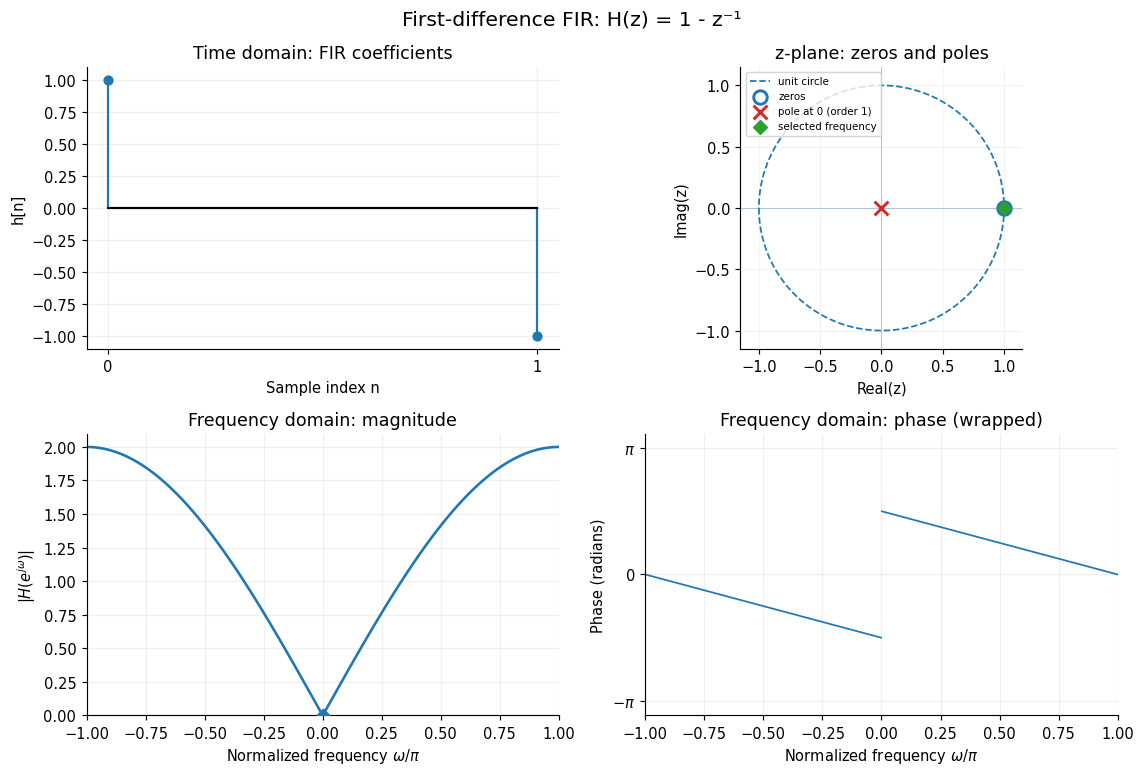

np.complex128(0j)

In [3]:
h = [1, -1]
print("Coefficients h[n] =", h)
print("Zeros:", fir_roots(h)[0], "| Poles at origin:", fir_roots(h)[1])
three_domain_plot(h, omega_probe=0, title='First-difference FIR: H(z) = 1 - z⁻¹')

## 2. Interactive exploration: edit the FIR coefficients

Choose a preset or type your own coefficients, separated by commas. The four views update together:

- **Top left:** $h[n]$, the FIR coefficients (the impulse response).
- **Top right:** the roots of $P(z)=z^M H(z)$ and the poles at the origin.
- **Bottom left:** $|H(e^{j\omega})|$ around the unit circle.
- **Bottom right:** phase response; phase is undefined at exact magnitude zeros.

The **frequency probe** moves the diamond on the unit circle and the matching points in the two frequency plots.

Notice: a zero **on** the unit circle at angle $\omega_0$ forces $H(e^{j\omega_0})=0$. A zero **inside or outside** the unit circle changes the response but usually does not produce an exact null.

In [ ]:
PRESETS = {
    'First difference [1, -1]': [1, -1],
    'Two-point moving average [1/2, 1/2]': [0.5, 0.5],
    'Three-point smoother [1/4, 1/2, 1/4]': [0.25, 0.5, 0.25],
    'Notch at ±π/4': [1, -np.sqrt(2), 1],
    '10-point running sum': [1] * 10,
    'Real cosine band-pass, L=10, ω₀=0.4π': np.cos(0.4 * np.pi * np.arange(10)).tolist(),
    'Symmetric 5-tap FIR': [1, 2, 3, 2, 1],
}

if HAS_WIDGETS:
    preset = widgets.Dropdown(options=list(PRESETS), value='Notch at ±π/4', description='Example:',
                              style={'description_width': 'initial'}, layout=widgets.Layout(width='475px'))
    coeff_box = widgets.Text(value='1, -1.414213562, 1', description='h[n]:',
                             continuous_update=False, style={'description_width': 'initial'},
                             layout=widgets.Layout(width='550px'))
    probe1 = widgets.FloatSlider(value=0.25, min=-1, max=1, step=0.025,
                                 description='Probe ω/π:', continuous_update=False,
                                 style={'description_width': 'initial'},
                                 layout=widgets.Layout(width='475px'), readout_format='.3f')
    def set_preset(change):
        if change['name'] == 'value':
            coeff_box.value = ', '.join(f'{float(v):.8g}' for v in PRESETS[change['new']])
    preset.observe(set_preset, 'value')

    def update_coeff_view(coeff_text, omega_pi):
        try:
            hh = parse_coefficients(coeff_text)
            if len(hh) > 31:
                raise ValueError('For clarity, please enter at most 31 coefficients.')
            zeros, origin_poles = fir_roots(hh)
            display(Markdown('**System function:** $' + polynomial_tex(hh) + '$  \n'
                             + f'**Order:** {len(hh)-1} · **Finite zeros:** {len(zeros)} · '
                             + f'**Poles at the origin:** {origin_poles}'))
            val = three_domain_plot(hh, omega_probe=np.pi*omega_pi)
            display(Markdown(f'At $\\omega/\\pi={omega_pi:.3f}$: '
                             + f'$|H(e^{{j\\omega}})|={abs(val):.4g}$, '
                             + f'$\\angle H={np.angle(val):.4g}$ rad '
                             + ('(phase is undefined at a null).' if abs(val)<1e-8 else '.')))
        except Exception as exc:
            display(Markdown('**Invalid coefficients:** ' + str(exc)))

    editor_output = widgets.interactive_output(update_coeff_view,
                                                {'coeff_text': coeff_box, 'omega_pi': probe1})
    display(widgets.VBox([preset, coeff_box, probe1]), editor_output)
else:
    display(Markdown('**Static fallback:** install `ipywidgets` to edit coefficients with the GUI.'))
    three_domain_plot(PRESETS['Notch at ±π/4'], omega_probe=np.pi/4)

Output()

## 3. Design an FIR by moving its zeros

A real second-order FIR that has a **conjugate pair of zeros** at

$$z_{1,2}=re^{\pm j\omega_0}$$

has the system function

$$\begin{aligned}
H(z)&=(1-re^{j\omega_0}z^{-1})(1-re^{-j\omega_0}z^{-1})\\
&=\boxed{1-2r\cos(\omega_0)z^{-1}+r^2z^{-2}}.
\end{aligned}$$

Hence its coefficients are $\{1,-2r\cos(\omega_0),r^2\}$. Try the following:

1. Set **radius = 1**, **angle = 0.25** ($\omega_0=\pi/4$): the pair lies *on* the unit circle and creates exact nulls at $\pm\pi/4$.
2. Change the **angle**: the nulls move along the frequency axis.
3. Change the **radius** away from 1: the exact nulls become shallow minima.
4. Add a **fixed zero at $-1$**: this multiplies $H(z)$ by $(1+z^{-1})$, adding a null at $\omega=\pi$.

**Note:** the pole multiplicity at the origin is the FIR order in this $z^{-1}$ representation; these systems are still finite and stable.

In [5]:
def two_zero_fir(angle_pi=0.25, radius=1.0, extra_minus_one=False):
    theta = np.pi * angle_pi
    h = np.array([1, -2 * radius * np.cos(theta), radius**2])
    if extra_minus_one:
        h = np.convolve(h, [1, 1])
    return h

if HAS_WIDGETS:
    move_angle = widgets.FloatSlider(value=.25, min=0, max=1, step=.01,
                                     description='Zero angle ω₀/π:', continuous_update=False,
                                     style={'description_width': 'initial'}, layout=widgets.Layout(width='520px'))
    move_radius = widgets.FloatSlider(value=1., min=.2, max=1.5, step=.025,
                                      description='Zero radius r:', continuous_update=False,
                                      style={'description_width': 'initial'}, layout=widgets.Layout(width='520px'))
    fixed_zero = widgets.Checkbox(value=False, description='Add a fixed zero at z = −1')
    probe2 = widgets.FloatSlider(value=.25, min=-1, max=1, step=.025,
                                 description='Probe ω/π:', continuous_update=False,
                                 style={'description_width': 'initial'}, layout=widgets.Layout(width='520px'))
    def update_two_zero(angle_pi, radius, extra_minus_one, probe_pi):
        h = two_zero_fir(angle_pi, radius, extra_minus_one)
        display(Markdown('**Derived from the zero locations:** $' + polynomial_tex(h) + '$'))
        v = three_domain_plot(h, omega_probe=np.pi * probe_pi,
                              title='Moving a conjugate zero pair', show_distances=True)
        display(Markdown(f'At $\\omega={probe_pi:.3f}\\pi$: $|H(e^{{j\\omega}})|={abs(v):.4f}$.'))
    zero_output = widgets.interactive_output(update_two_zero,
            {'angle_pi': move_angle, 'radius': move_radius,
             'extra_minus_one': fixed_zero, 'probe_pi': probe2})
    display(widgets.VBox([move_angle, move_radius, fixed_zero, probe2]), zero_output)
else:
    three_domain_plot(two_zero_fir(), omega_probe=np.pi/4,
                      title='Conjugate zeros at ±π/4 (static fallback)', show_distances=True)

Output()

### Why zero locations control the magnitude response

For $H(z)=h[0]\prod_{m=1}^M(1-z_m z^{-1})$ (with $h[0]\ne0$),

$$|H(e^{j\omega})|=|h[0]|\prod_{m=1}^M |e^{j\omega}-z_m|.$$

The magnitude response is proportional to the **product of distances** from the unit-circle point $e^{j\omega}$ to all zeros $z_m$.

In the preceding display, move the **frequency probe** towards a zero. Its distance to that zero decreases, and so does $|H(e^{j\omega})|$. If they coincide, the distance and magnitude are zero.

## 4. Running sum and band-pass: roots around the unit circle

An $L$-point **running sum** has all-one coefficients:

$$h[n]=\begin{cases}1,&0\le n<L,\\0,&\text{otherwise},\end{cases}
\qquad H(z)=1+z^{-1}+\cdots+z^{-(L-1)}=\frac{1-z^{-L}}{1-z^{-1}}.$$

Its zeros are the $L$th roots of unity **except** $z=1$ (which cancels). So DC is passed with gain $L$, while the frequencies $\omega=2\pi k/L$ for $k=1,\ldots,L-1$ are nulled.

Now use a simple **complex modulation** $h_c[n]=e^{j\omega_0 n}$, $0\le n<L$: this moves the main passband from $0$ to $\omega_0$. Taking the real part $h_r[n]=\cos(\omega_0 n)$ creates symmetric bands around $\pm\omega_0$.

The next comparison uses $L=10$ and $\omega_0=0.4\pi$, matching the type of example in T7. The three filters have related coefficient patterns but different zero patterns and frequency selectivity.

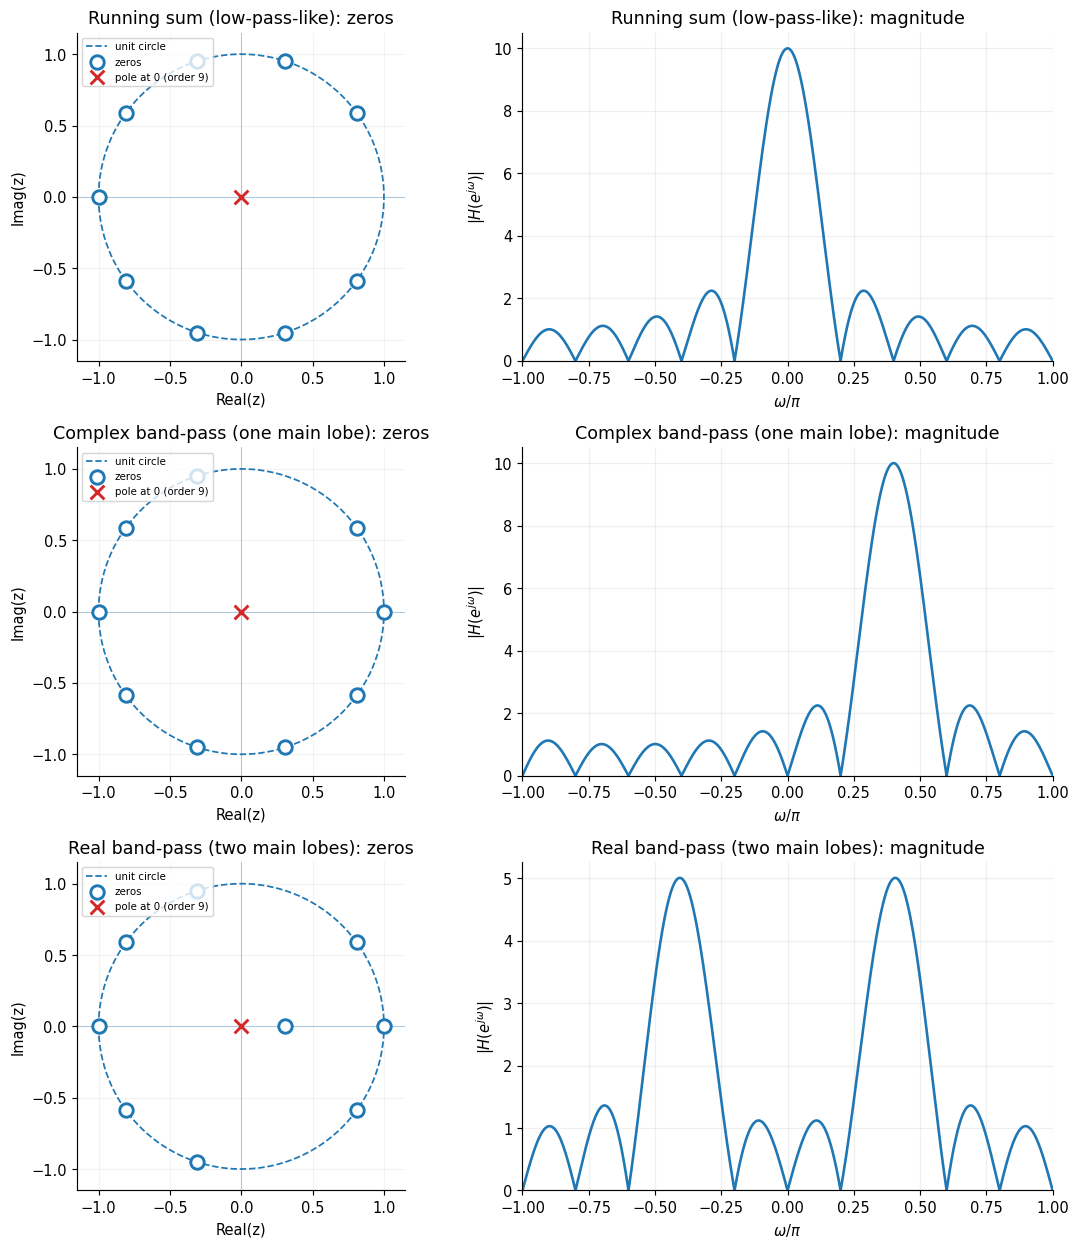

Running-sum zeros (angles as fractions of π):
[-0.8 -0.6 -0.4 -0.2  0.2  0.4  0.6  0.8  1. ]


In [6]:
def plot_running_sum_family(L=10, omega0_pi=.4):
    n = np.arange(L)
    h_sum = np.ones(L)
    h_complex = np.exp(1j * np.pi * omega0_pi * n)
    h_real = np.cos(np.pi * omega0_pi * n)
    w = np.linspace(-np.pi, np.pi, 1501)
    fig, axes = plt.subplots(3, 2, figsize=(10.8, 12))
    for row, (name, h) in enumerate([
        ('Running sum (low-pass-like)', h_sum),
        ('Complex band-pass (one main lobe)', h_complex),
        ('Real band-pass (two main lobes)', h_real),
    ]):
        draw_zplane(axes[row, 0], h)
        axes[row, 0].set_title(name + ': zeros')
        axes[row, 1].plot(w/np.pi, np.abs(fir_response(h, w)), lw=1.8)
        axes[row, 1].set(xlim=(-1, 1), ylim=(0,None), xlabel=r'$\omega/\pi$',
                        ylabel=r'$|H(e^{j\omega})|$', title=name + ': magnitude')
        axes[row, 1].grid(alpha=.2)
    fig.tight_layout()
    plt.show()
    return h_sum, h_complex, h_real

h_sum, h_complex, h_real = plot_running_sum_family(L=10, omega0_pi=.4)
print('Running-sum zeros (angles as fractions of π):')
print(np.round(np.sort(np.angle(np.roots(h_sum))/np.pi), 2))

### Experiment: move roots of unity radially (as in the DSPFirst videos)

The running sum has nine zeros distributed around the unit circle. You can **move one conjugate pair** of those zeros toward or away from the origin, while keeping all the others fixed. The notch at the associated frequencies disappears as soon as the pair leaves the circle.

You can also **add the missing zero at $z=1$**. When all ten roots of unity are included, the system function becomes $H(z)=1-z^{-10}$, a *comb difference* filter rather than a running sum. In the second mode, move this added root along the real axis to see the DC null change. These reproduce the central idea of the ten-zero animations, with the coefficients, zeros, and frequency response updating together.


In [7]:
def altered_roots_filter(mode='Conjugate pair', radius=1.0, k=2, L=10):
    # np.poly returns coefficients of P(z); these are also h[k] in z^(-1).
    if mode == 'Conjugate pair':
        # Running sum: the Lth roots of unity EXCEPT root k=0 (z=1).
        roots = np.exp(2j * np.pi * np.arange(1, L) / L)
        roots[k-1] = radius * np.exp(2j * np.pi * k / L)
        roots[L-k-1] = radius * np.exp(-2j * np.pi * k / L)
    else:
        # Comb difference: include all L roots of unity, then move z=1 radially.
        roots = np.exp(2j * np.pi * np.arange(L) / L)
        roots[0] = radius
    return np.real_if_close(np.poly(roots), tol=1000)

if HAS_WIDGETS:
    root_mode = widgets.Dropdown(options=['Conjugate pair', 'Single root at z=1'],
                                 description='Move:', style={'description_width': 'initial'},
                                 layout=widgets.Layout(width='370px'))
    root_k = widgets.IntSlider(value=2, min=1, max=4, step=1, description='Pair k:',
                               continuous_update=False, style={'description_width': 'initial'},
                               layout=widgets.Layout(width='480px'))
    root_r = widgets.FloatSlider(value=1, min=.25, max=1.5, step=.025,
                                 description='New radius:', continuous_update=False,
                                 style={'description_width': 'initial'},
                                 layout=widgets.Layout(width='480px'))
    def update_root_family(mode, r, k):
        hh = altered_roots_filter(mode, r, k)
        where = (f'±{2*k/10:.2g}π' if mode=='Conjugate pair' else '0 (DC)')
        display(Markdown(f'**Selected zero angle(s):** {where}.  '
                         + f'**FIR order:** {len(hh)-1}.'))
        three_domain_plot(hh, omega_probe=(2*np.pi*k/10 if mode=='Conjugate pair' else 0),
                          title='Moving roots around / away from the unit circle')
    out_roots = widgets.interactive_output(update_root_family,
                                           {'mode': root_mode, 'r': root_r, 'k': root_k})
    display(widgets.VBox([root_mode, root_k, root_r]), out_roots)
else:
    three_domain_plot(altered_roots_filter('Conjugate pair', .85, 2),
                      omega_probe=2*np.pi/5,
                      title='Running-sum zeros: one conjugate pair moved inward')

Output()

## 5. See the **z-domain surface** and its unit-circle trace

The function $H(z)$ is defined over the complex $z$-plane (apart from its poles). On the unit circle,

$$z=e^{j\omega}\quad\Longrightarrow\quad H(z)=H(e^{j\omega}),$$

which is precisely the **frequency response**. The next visualization draws a 3D surface of $\log(1+|H(z)|)$, then highlights the curve traced by the unit circle over that surface. A logarithmic vertical scale makes both small valleys and large peaks visible.

The right-hand plot shows the *same unit-circle values* as an ordinary magnitude frequency response. Move the probe frequency to identify corresponding points on the surface and frequency curve. **This surface is a visualization, not a second definition of the Fourier transform.**

In [8]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (enables 3D projections)

def z_surface_plot(h, omega_probe=np.pi/4, resolution=95):
    h = clean_coefficients(h)
    t = np.linspace(-1.48, 1.48, resolution)
    X, Y = np.meshgrid(t, t)
    Z = X + 1j*Y
    mag = np.abs(hz_on_plane(h, Z))
    surface = np.log1p(mag)
    surface[np.abs(Z) < .20] = np.nan  # exclude the origin, where an FIR may have a pole
    surface = np.clip(surface, 0, 5)    # clip tall peaks for a readable graphic
    theta = np.linspace(-np.pi, np.pi, 601)
    circle_z = np.exp(1j*theta)
    circle_height = np.log1p(np.abs(fir_response(h, theta)))
    p = np.exp(1j*omega_probe)
    hp = np.abs(fir_response(h, [omega_probe])[0])
    fig = plt.figure(figsize=(13, 5.5))
    ax = fig.add_subplot(1, 2, 1, projection='3d')
    ax.plot_surface(X, Y, surface, cmap='viridis', alpha=.77,
                    linewidth=0, antialiased=True, rstride=2, cstride=2)
    ax.plot(circle_z.real, circle_z.imag, circle_height, color='black', lw=2.8,
            label='unit-circle trace')
    ax.scatter([p.real], [p.imag], [np.log1p(hp)], color='C3', s=65)
    ax.set(xlabel='Real(z)', ylabel='Imag(z)', zlabel=r'$\log(1+|H(z)|)$',
           title='The z-domain magnitude surface')
    ax.view_init(elev=32, azim=-63)
    ax.legend(loc='upper right', fontsize=8)
    ax2 = fig.add_subplot(1, 2, 2)
    ax2.plot(theta/np.pi, np.abs(fir_response(h, theta)), lw=2)
    ax2.scatter([omega_probe/np.pi], [hp], s=55, color='C3', zorder=4)
    ax2.set(xlim=(-1, 1), ylim=(0,None), xlabel=r'Normalized frequency $\omega/\pi$',
            ylabel=r'$|H(e^{j\omega})|$', title='Trace of the unit circle = frequency response')
    ax2.grid(alpha=.2)
    fig.tight_layout()
    plt.show()

if HAS_WIDGETS:
    surface_choice = widgets.Dropdown(options=['First difference', 'Notch at ±π/4',
                                     '10-point running sum', 'Symmetric 5-tap FIR'],
                                      description='Filter:', style={'description_width': 'initial'},
                                      layout=widgets.Layout(width='340px'))
    probe3 = widgets.FloatSlider(value=.25, min=-1, max=1, step=.025,
                                 description='Probe ω/π:', continuous_update=False,
                                 style={'description_width': 'initial'},
                                 layout=widgets.Layout(width='480px'))
    SURFACE_COEFFS = {
        'First difference': [1, -1],
        'Notch at ±π/4': [1, -np.sqrt(2), 1],
        '10-point running sum': [1]*10,
        'Symmetric 5-tap FIR': [1, 2, 3, 2, 1],
    }
    def update_surface(name, probe_pi):
        z_surface_plot(SURFACE_COEFFS[name], probe_pi*np.pi)
    out3 = widgets.interactive_output(update_surface,
                                      {'name': surface_choice, 'probe_pi': probe3})
    display(widgets.VBox([surface_choice, probe3]), out3)
else:
    z_surface_plot([1, -np.sqrt(2), 1], np.pi/4)

Output()

## 6. Verify a zero using a sinusoidal input

For an LTI FIR filter, a complex exponential $x[n]=e^{j\omega n}$ is an eigenfunction: the filter multiplies it by $H(e^{j\omega})$. For a real cosine, the same magnitude/phase relationship applies in the steady-state part of the output.

Take the notch filter

$$H(z)=1-\sqrt{2}z^{-1}+z^{-2},$$

with zeros at $e^{\pm j\pi/4}$. At $\omega=\pi/4$, a continuous cosine should be suppressed *once the initial boundary transient has passed*. Because a finite input starts at $n=0$ with no earlier samples, the first $M$ output samples can contain a transient, even when the selected frequency is an exact zero.

Move the input frequency slightly away from $\pi/4$ to see the sinusoid reappear.

In [9]:
def show_nulling_in_time(input_omega_pi=.25):
    n = np.arange(80)
    h = np.array([1, -np.sqrt(2), 1])
    x = np.cos(np.pi*input_omega_pi*n)
    y = np.convolve(x, h)[:len(n)]
    gain = abs(fir_response(h, [np.pi*input_omega_pi])[0])
    fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
    axes[0].plot(n, x, marker='.', lw=1)
    axes[0].set(ylabel='x[n]', title='Input: cosine at ω = %.2fπ' % input_omega_pi)
    axes[1].plot(n, y, marker='.', lw=1)
    axes[1].axvline(len(h)-1, ls='--', lw=1, color='0.4', label='end of start-up transient')
    axes[1].set(xlabel='Sample index n', ylabel='y[n]',
                title='Filtered output: theoretical steady-state gain = %.4g' % gain)
    axes[1].legend(fontsize=8)
    for ax in axes: ax.grid(alpha=.2)
    fig.tight_layout()
    plt.show()

if HAS_WIDGETS:
    input_slider = widgets.FloatSlider(value=.25, min=.05, max=.8, step=.025,
                                       description='Input ω/π:', continuous_update=False,
                                       style={'description_width': 'initial'},
                                       layout=widgets.Layout(width='475px'))
    out4 = widgets.interactive_output(show_nulling_in_time,
                                      {'input_omega_pi': input_slider})
    display(input_slider, out4)
else:
    show_nulling_in_time(.25)

FloatSlider(value=0.25, continuous_update=False, description='Input ω/π:', layout=Layout(width='475px'), max=0…

Output()

## 7. Questions to work through

1. **Low-pass versus high-pass.** Starting from $h[n]=\{1,1\}$, determine $H(z)$ and the zero location. Predict which frequency is suppressed. Now change to $h[n]=\{1,-1\}$: what changes?
2. **Moving a notch.** Use the conjugate-zero sliders to set $r=1$ and $\omega_0=0.6\pi$. Write the three coefficients, and verify both frequency nulls.
3. **Inside the unit circle.** At the same angle, move the zeros to $r=0.7$. Why does the magnitude no longer reach zero on the unit circle?
4. **Running sum.** For $L=10$, predict the nine non-DC zero angles before viewing the running-sum example. Explain why $|H(1)|=10$ even though $1-z^{-10}=0$ at $z=1$.
5. **Band-pass.** For a real-valued filter, why should a passband at $+0.4\pi$ be accompanied by a passband at $-0.4\pi$?
6. **Linear phase.** Try the symmetric five-tap preset. Check that $h[n]=h[M-n]$ and that (between possible $\pi$ phase jumps) the phase has a slope corresponding to a delay $M/2$.

**Quick self-check:** (1) $1+z^{-1}$ has a zero at $-1$ ($\omega=\pi$); $1-z^{-1}$ has a zero at $+1$ (DC). (2) $h=\{1,-2\cos(0.6\pi),1\}$. (3) A unit-circle point cannot coincide with a zero of radius $0.7$. (4) The geometric-series expression has a removable $0/0$ at $z=1$; the original sum is 10. (5) Real coefficients imply $H(e^{-j\omega})=H^*(e^{j\omega})$. (6) The center of symmetry is $M/2=2$ samples.

## Summary and sources

- **FIR impulse response:** $h[n]$ is both the coefficient sequence and the time-domain response to an impulse.
- **System function:** $H(z)=\sum h[k]z^{-k}$.
- **Zeros:** find the roots of $P(z)=z^M H(z)$ and examine their geometry in the z-plane.
- **Frequency response:** $H(e^{j\omega})$ is the unit-circle evaluation of $H(z)$.
- **Design insight:** move zeros to control null frequencies; conjugate pairs produce real FIR coefficients.
- **Moving-average/running-sum and band-pass examples:** their zero patterns explain passband and stopband locations.

This is an original notebook inspired by McClellan, Schafer & Yoder, *Signal Processing First / DSP First*, and specifically the linked [PEZ Demo](https://dspfirst.gatech.edu/matlab/#pezdemo) and [Three-Domain Connections](https://dspfirst.gatech.edu/chapters/07ztrans/demos/3_domain/index.html) videos. It also follows the topic sequence in the provided T7 lecture document.